## Set configuration and attack parameters

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, random_split
from sklearn.preprocessing import label_binarize
import numpy as np
import copy
import random
import torch.nn.functional as F
import matplotlib.pyplot as plt
# configuration
batch_size = 128
epochs = 15
learning_rate = 1e-3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# set seed for reproducibility
torch.manual_seed(0)
np.random.seed(0)
random.seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# attack parameters
# number of iterations for I-FGSM and MI-FGSM
iters = 10
# step size is set per epsilon (alpha = 2.5 * eps / iters)
def step_size(eps): return 2.5 * eps / iters
decay = 1.0

## Load MNIST data

In [2]:
# load data
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Set up three models (MLP, CNN, Transformer Encoder)

In [3]:
# create three models:
# 1. a shallow Multi-Layer Perceptron (MLP)
# 2. a Convolutional Neural Network (CNN)
# 3. a Transformer (Encoder)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class Transformer_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_size = 7
        self.embed_dim = 64
        self.patch_proj = nn.Linear(7 * 7, self.embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, self.embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 16 + 1, self.embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.embed_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=2,
            norm=nn.LayerNorm(self.embed_dim),
            enable_nested_tensor=False
        )
        self.head = nn.Linear(self.embed_dim, 10)

    def forward(self, x):
        B = x.shape[0]
        patches = x.unfold(2, self.patch_size, self.patch_size).unfold(3, self.patch_size, self.patch_size)
        patches = patches.contiguous().view(B, 16, -1)
        x = self.patch_proj(patches)
        x = torch.cat((self.cls_token.expand(B, -1, -1), x), dim=1) + self.pos_embed
        return self.head(self.transformer(x)[:, 0, :])

## Set up three attacks (FGSM, I-FGSM, MI-FGSM)

In [4]:
# define three attacks
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def ifgsm_attack(model, images, labels, epsilon, alpha, iters):
    original_images = images.clone().detach()
    perturbed_images = images.clone().detach()

    for _ in range(iters):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        model.zero_grad()
        loss = F.cross_entropy(outputs, labels)
        loss.backward()

        # iterative step
        adv_images = perturbed_images + alpha * perturbed_images.grad.sign()

        eta = torch.clamp(adv_images - original_images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(original_images + eta, min=0, max=1).detach()

    return perturbed_images

def mifgsm_attack(model, images, labels, epsilon, alpha, iters, decay=1.0):
    original_images = images.clone().detach()
    perturbed_images = images.clone().detach()
    momentum = torch.zeros_like(images).detach()

    for _ in range(iters):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        model.zero_grad()
        loss = F.cross_entropy(outputs, labels)
        loss.backward()

        grad = perturbed_images.grad.data

        # normalize gradient for momentum update - L1 norm per image
        grad_norm = torch.norm(grad, p=1, dim=(1,2,3), keepdim=True)
        grad_norm = torch.clamp(grad_norm, min=1e-12)
        grad = grad / grad_norm

        momentum = decay * momentum + grad

        # apply perturbation
        adv_images = perturbed_images + alpha * momentum.sign()

        eta = torch.clamp(adv_images - original_images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(original_images + eta, min=0, max=1).detach()

    return perturbed_images

In [5]:
# model training
def train_model(model, name):
    print(f"\n--- Training {name} ---")
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = F.cross_entropy(output, target)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")
    return model

## define functions for recognition rate/attack success rate (ASR) calculation

In [6]:
# define range of perturbation magnitudes to test
epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]


def evaluate_clean(model, loader):
    # recognition rate before attacks (test-set accuracy)
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            correct += (model(data).argmax(1) == target).sum().item()
            total += target.size(0)
    return 100.0 * correct / total


def evaluate_epsilons_and_plot(models_dict, test_loader, epsilons, iters, decay):
    all_asr_results = {name: {'FGSM': [], 'I-FGSM': [], 'MI-FGSM': []} for name in models_dict.keys()}
    clean_acc = {}

    for name, model in models_dict.items():
        model.eval()
        clean_acc[name] = evaluate_clean(model, test_loader)
        print(f"\n--- {name}: recognition rate before attacks = {clean_acc[name]:.2f}% ---")

        for eps in epsilons:
            alpha = step_size(eps)
            n_clean_correct = 0
            fooled = {'FGSM': 0, 'I-FGSM': 0, 'MI-FGSM': 0}

            for data, target in test_loader:
                data, target = data.to(device), target.to(device)

                # clean prediction + gradient for FGSM
                x = data.clone().requires_grad_(True)
                output = model(x)
                clean_ok = output.argmax(1) == target
                n_clean_correct += clean_ok.sum().item()
                if eps == 0:
                    continue

                loss = F.cross_entropy(output, target)
                model.zero_grad()
                loss.backward()

                advs = {
                    'FGSM': fgsm_attack(data, eps, x.grad),
                    'I-FGSM': ifgsm_attack(model, data, target, eps, alpha, iters),
                    'MI-FGSM': mifgsm_attack(model, data, target, eps, alpha, iters, decay),
                }
                with torch.no_grad():
                    for k, adv in advs.items():
                        adv_wrong = model(adv).argmax(1) != target
                        fooled[k] += (clean_ok & adv_wrong).sum().item()

            for k in fooled:
                asr = 100.0 * fooled[k] / n_clean_correct
                all_asr_results[name][k].append(asr)
            print(f"  \u03B5={eps:<5} ASR  FGSM {all_asr_results[name]['FGSM'][-1]:6.2f}%  "
                  f"I-FGSM {all_asr_results[name]['I-FGSM'][-1]:6.2f}%  "
                  f"MI-FGSM {all_asr_results[name]['MI-FGSM'][-1]:6.2f}%")

    # plot epsilons vs. asr for each attack
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Attack Success Rate (ASR) vs Epsilon', fontsize=16, fontweight='bold')

    for i, (name, attack_data) in enumerate(all_asr_results.items()):
        ax = axes[i]
        ax.plot(epsilons, attack_data['FGSM'], marker='o', label='FGSM', linestyle='-')
        ax.plot(epsilons, attack_data['I-FGSM'], marker='s', label='I-FGSM', linestyle='--')
        ax.plot(epsilons, attack_data['MI-FGSM'], marker='^', label='MI-FGSM', linestyle='-.')

        ax.set_title(f'Model: {name} (recognition rate before attacks:{clean_acc[name]:.2f}%)')
        ax.set_xlabel('Epsilon (\u03B5)')
        ax.set_ylabel('Attack Success Rate (%)')
        ax.set_ylim(-5, 105)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend()

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)

    plt.savefig('asr_vs_epsilon.png', dpi=300)
    plt.show()
    return clean_acc, all_asr_results

## Model training

In [7]:
models = {
    "MLP": MLP(),
    "CNN": CNN(),
    "Transformer Encoder": Transformer_Encoder()
}

for name, model in models.items():
    train_model(model, name)


--- Training MLP ---
Epoch 1/15 - Loss: 0.3471
Epoch 2/15 - Loss: 0.1340
Epoch 3/15 - Loss: 0.0908
Epoch 4/15 - Loss: 0.0675
Epoch 5/15 - Loss: 0.0506
Epoch 6/15 - Loss: 0.0377
Epoch 7/15 - Loss: 0.0312
Epoch 8/15 - Loss: 0.0250
Epoch 9/15 - Loss: 0.0199
Epoch 10/15 - Loss: 0.0140
Epoch 11/15 - Loss: 0.0146
Epoch 12/15 - Loss: 0.0112
Epoch 13/15 - Loss: 0.0153
Epoch 14/15 - Loss: 0.0098
Epoch 15/15 - Loss: 0.0063

--- Training CNN ---
Epoch 1/15 - Loss: 0.3025
Epoch 2/15 - Loss: 0.0674
Epoch 3/15 - Loss: 0.0501
Epoch 4/15 - Loss: 0.0362
Epoch 5/15 - Loss: 0.0296
Epoch 6/15 - Loss: 0.0237
Epoch 7/15 - Loss: 0.0200
Epoch 8/15 - Loss: 0.0161
Epoch 9/15 - Loss: 0.0132
Epoch 10/15 - Loss: 0.0109
Epoch 11/15 - Loss: 0.0098
Epoch 12/15 - Loss: 0.0089
Epoch 13/15 - Loss: 0.0070
Epoch 14/15 - Loss: 0.0057
Epoch 15/15 - Loss: 0.0056

--- Training Transformer Encoder ---
Epoch 1/15 - Loss: 0.6182
Epoch 2/15 - Loss: 0.2260
Epoch 3/15 - Loss: 0.1721
Epoch 4/15 - Loss: 0.1406
Epoch 5/15 - Loss: 0.1

## calculate recognition rate before attacks and print/plot attack success rate (ASR)


--- MLP: recognition rate before attacks = 97.20% ---
  ε=0     ASR  FGSM   0.00%  I-FGSM   0.00%  MI-FGSM   0.00%
  ε=0.05  ASR  FGSM  39.98%  I-FGSM  51.00%  MI-FGSM  49.84%
  ε=0.1   ASR  FGSM  74.67%  I-FGSM  94.36%  MI-FGSM  92.98%
  ε=0.15  ASR  FGSM  90.46%  I-FGSM  99.80%  MI-FGSM  99.69%
  ε=0.2   ASR  FGSM  96.62%  I-FGSM 100.00%  MI-FGSM 100.00%
  ε=0.25  ASR  FGSM  98.72%  I-FGSM 100.00%  MI-FGSM 100.00%
  ε=0.3   ASR  FGSM  99.56%  I-FGSM 100.00%  MI-FGSM 100.00%

--- CNN: recognition rate before attacks = 98.92% ---
  ε=0     ASR  FGSM   0.00%  I-FGSM   0.00%  MI-FGSM   0.00%
  ε=0.05  ASR  FGSM   3.38%  I-FGSM   4.59%  MI-FGSM   4.59%
  ε=0.1   ASR  FGSM  14.59%  I-FGSM  27.19%  MI-FGSM  26.11%
  ε=0.15  ASR  FGSM  31.28%  I-FGSM  78.17%  MI-FGSM  73.10%
  ε=0.2   ASR  FGSM  47.64%  I-FGSM  98.80%  MI-FGSM  97.60%
  ε=0.25  ASR  FGSM  62.66%  I-FGSM  99.92%  MI-FGSM  99.85%
  ε=0.3   ASR  FGSM  73.93%  I-FGSM  99.98%  MI-FGSM  99.97%

--- Transformer Encoder: recognitio

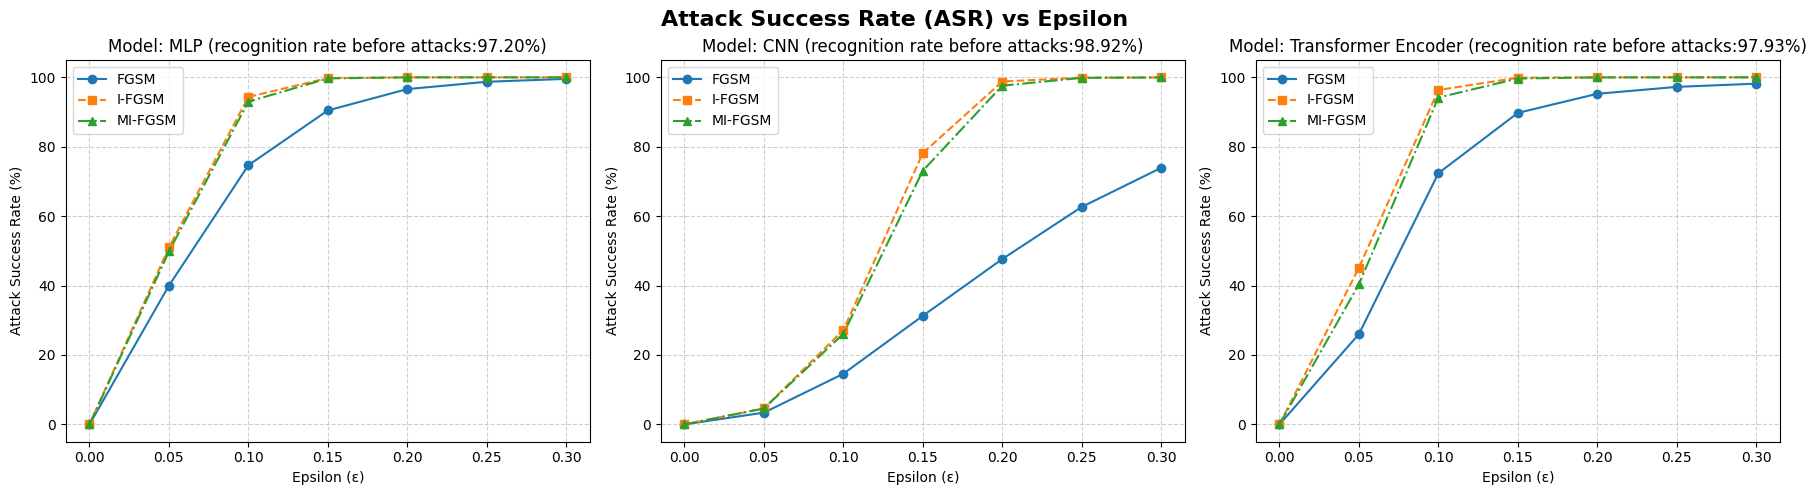

In [8]:
# evaluation and plot
clean_acc, asr_results = evaluate_epsilons_and_plot(models, test_loader, epsilons, iters, decay)

## download attack results and graph

In [9]:
import json
from google.colab import files

results = {
    "clean_recognition_rate": clean_acc,
    "epsilons": epsilons,
    "asr": asr_results,
    "attack_params": {"iters": iters, "decay": decay, "alpha": "2.5 * eps / iters"},
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

files.download("results.json")
files.download("asr_vs_epsilon.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>